# 02 — EDA textual da base ALTA: o que torna este Entity Matching difícil

**Para que serve este notebook.** É o registro de pesquisa da análise exploratória textual e o material de apoio direto para escrever a **Seção 1 (Introdução)** e o **§4.7 (Caracterização da base)** do `main.tex`. Cada bloco traz o número, um exemplo real e um parágrafo de interpretação.

**De onde vêm os números.** Toda a extração reaproveita as funções já testadas de `scripts/02_analise_exploratoria.py` (EDA) e `scripts/01_coleta_dados.py` (limpeza). Este notebook não reimplementa lógica de extração, não gera tabela/figura para `latex/` e não altera o `main.tex`. Amostragens usam `SEED = 42`, a mesma do sanity check.

**Restrições respeitadas (ADR-0011).** O modelo só vê texto (`description`, `desc_alim`). As colunas do matcher ALTA (`codg_item`, `desc_ref`, `match_score`) não são exibidas, filtradas nem usadas como sinal aqui; só aparecem como limitação documentada do baseline. A blocagem (tarefa 1.2) não é antecipada.

**Ponto de partida.** O `notebooks/01_sanity_check.ipynb` concluiu: 0 bloqueantes, 8 warnings, 7 informativos, 21 verificações ok. A Seção 6 trata os warnings que pedem tratamento.

**Qual base é descrita (ADR-0012).** As Seções 2–5 descrevem a **base limpa** (29.130 registros), a mesma que gera as tabelas de `latex/` e que todo o pipeline consome. A Seção 6 documenta como ela é produzida a partir dos 30.259 registros coletados.

In [1]:
import importlib.util
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

SEED = 42
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())


def carregar_script(nome: str, arquivo: str):
    spec = importlib.util.spec_from_file_location(nome, RAIZ / "scripts" / arquivo)
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    return modulo


eda = carregar_script("eda", "02_analise_exploratoria.py")
coleta = carregar_script("coleta", "01_coleta_dados.py")
%matplotlib inline

# Base oficial (ADR-0012): o script 01 grava a base limpa; a EDA a descreve.
relatorio = coleta.executar_limpeza(RAIZ / "dados" / "brutos", RAIZ / "dados" / "processados")
base, dicionario = eda.carregar_base_limpa(RAIZ / "dados" / "processados")
# Brutos: usados só na Seção 6, para mostrar o que a limpeza fez.
bruto = eda.carregar_produtos(RAIZ / "dados" / "brutos")
dicionario_bruto = eda.carregar_dicionario(RAIZ / "dados" / "brutos")

# ADR-0011: nunca exibir as colunas do matcher ALTA.
VISIVEIS = ["product_id", "description", "unit", "price", "location", "source", "collected_at"]
print(f"Base limpa: {len(base):,} registros (coletados: {len(bruto):,}) | dicionário: {len(dicionario):,} entradas")

2026-10-06 12:08:05,920 INFO Produtos coletados: todos_mercados_2026-09-10.csv (30259 linhas, 13 colunas)


2026-10-06 12:08:05,922 INFO Dicionário canônico: dicionario_canonico.csv (1593 entradas)


2026-10-06 12:08:06,050 INFO Limpeza: 30259 → 29130 registros (1129 duplicatas exatas removidas).


Base limpa: 29,130 registros (coletados: 30,259) | dicionário: 1,593 entradas


## 1. Introdução: por que olhar o texto antes de modelar

O `main.tex` (L170) define o problema: **o mesmo produto físico aparece descrito com nomes radicalmente distintos entre supermercados**, e o objetivo principal é identificar quando descrições de lojas diferentes se referem ao mesmo produto, com o mapeamento a um dicionário canônico como fatia secundária (L172; ADR-0014). Em seguida (L174–182) lista seis desafios que tornariam as abordagens clássicas insuficientes: abreviação/truncamento, inversão de tokens, unidades de medida alternativas, variação de granularidade, marcas regionais pouco representadas e ruído tipográfico.

Até aqui essas afirmações estavam apoiadas em exemplos. Este notebook as transforma em **medidas sobre os 29.130 registros da base limpa** (30.259 coletados, menos 1.129 duplicatas exatas). Isso importa por dois motivos: (1) a banca precisa ver que a dificuldade é empírica, não retórica; (2) cada tipo de ruído medido aqui vira uma categoria da análise de erro da Fase 4, então defini-los agora com números evita reclassificar depois.

## 2. Visão geral da base

In [2]:
contagens = eda.calcular_contagens_basicas(base, dicionario)
datas = pd.to_datetime(base["collected_at"])

visao = pd.Series({
    "registros": f"{contagens['total_registros']:,}",
    "redes (source)": contagens["distribuicao_source"].__len__(),
    "locais (location)": contagens["numero_estabelecimentos"],
    "product_id distintos": f"{contagens['product_id_distintos']:,}",
    "descrições distintas": f"{contagens['descricoes_distintas']:,}",
    "entradas do dicionário": f"{contagens['total_entradas_dicionario']:,}",
    "período de coleta": f"{datas.min():%d/%m/%Y %H:%M} a {datas.max():%H:%M}",
    "sobreposição exata entre lojas": f"{contagens['taxa_sobreposicao_lojas']:.1%}",
})
display(visao.to_frame("valor"))
display(pd.Series(contagens["distribuicao_estado"], name="registros por estado").to_frame())
display(pd.Series(contagens["distribuicao_location"], name="registros por local").to_frame())

,valor
registros,"29,130"
redes (source),8
locais (location),7
product_id distintos,"26,016"
descrições distintas,"28,602"
entradas do dicionário,"1,593"
período de coleta,10/09/2026 12:28 a 12:40
sobreposição exata entre lojas,2.1%


,registros por estado
PB,10286
PI,9881
CE,8963


,registros por local
"PI, Teresina, Vermelha",9206
"PB, Patos, Centro",6943
"CE, Limoeiro do Norte, Socorro",6045
"PB, João Pessoa, Pedro Gondim",3343
"CE, Várias Unidades",1625
"CE, Fortaleza, Papicu",1293
"PI, Teresina, Santa Isabel",675


**Interpretação.** São 29.130 registros (dos 30.259 coletados, após remover 1.129 duplicatas exatas) de 8 redes, cobrindo os três estados de forma equilibrada (PB 10.286, PI 9.881, CE 8.963), contra um dicionário de 1.593 entradas genéricas. Na coleta bruta, PI aparecia como o maior estado (10.909); a diferença eram duplicatas da `extra_api`, toda em Teresina. A sobreposição *exata* de texto entre lojas é de só 2,1%. Isso não significa que as lojas vendem produtos diferentes — significa que, quando vendem o mesmo produto, quase nunca o descrevem com o mesmo texto. É a primeira evidência quantitativa do problema.

**Limitação a citar no §4.7 — dia único.** Toda a coleta aconteceu em **10/09/2026, entre 12:28 e 12:40**. É um retrato pontual: não há série temporal nesta versão dos dados, então nada aqui permite afirmar estabilidade das descrições ao longo do tempo (ex.: se uma loja muda a grafia de um produto entre semanas). Isso deve aparecer no §4.7 como limitação explícita, não implícita.

> ⚠️ **Inconsistência com o `main.tex` (identificada aqui; ver Seção 7).** O §4.7 prometia reportar o "número de estabelecimentos". Dos 7 valores de `location`, um é `CE, Várias Unidades` (1.625 registros, todos da `diniz_api`): um agregado de lojas, não um estabelecimento. São **6 estabelecimentos identificáveis + 1 agregado**. O mesmo parágrafo trazia 30.260 registros; o arquivo tem 30.259 (e 29.130 depois da limpeza, Seção 6).

## 3. Granularidade descritiva: o PDV fala mais que o dicionário

,caracteres — PDV,caracteres — dicionário,tokens — PDV,tokens — dicionário
mean,38.7,18.0,6.3,2.9
std,13.6,10.6,2.2,1.7
50%,36.0,16.0,6.0,3.0
min,5.0,3.0,1.0,1.0
max,156.0,80.0,26.0,11.0


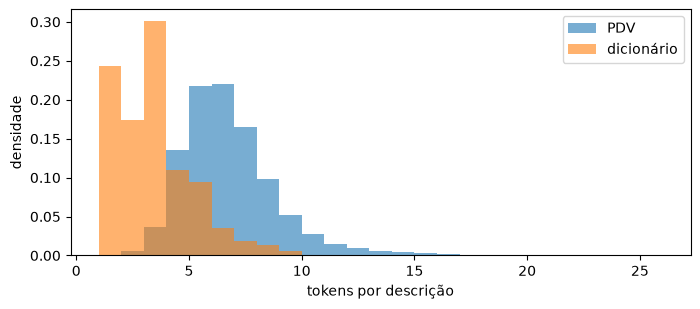

In [3]:
comprimentos = eda.comparar_comprimentos(base, dicionario)
tabela = pd.DataFrame({
    "caracteres — PDV": comprimentos["caracteres_bruto"],
    "caracteres — dicionário": comprimentos["caracteres_dicionario"],
    "tokens — PDV": comprimentos["tokens_bruto"],
    "tokens — dicionário": comprimentos["tokens_dicionario"],
}).loc[["mean", "std", "50%", "min", "max"]].round(1)
display(tabela)

tok_pdv = base["description"].map(lambda t: len(eda.tokenizar(t)))
tok_dic = dicionario["desc_alim"].map(lambda t: len(eda.tokenizar(t)))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(tok_pdv, bins=range(1, 27), alpha=.6, density=True, label="PDV")
ax.hist(tok_dic, bins=range(1, 27), alpha=.6, density=True, label="dicionário")
ax.set_xlabel("tokens por descrição"); ax.set_ylabel("densidade"); ax.legend(); plt.show()

**Interpretação.** Uma descrição de PDV tem em média **38,7 caracteres / 6,3 tokens**; uma entrada do dicionário, **18,0 / 2,9** — o PDV é cerca de duas vezes mais longo. A diferença não é ruído: é informação que o dicionário deliberadamente não tem. O PDV carrega marca, embalagem, tamanho e variante (`Arroz Integral Tio João 7 Grãos com quinoa 500g`); o dicionário guarda só o produto genérico (`ARROZ INTEGRAL`). Para o matching, isso significa que o par é **assimétrico**: o modelo precisa decidir quais tokens do lado PDV são relevantes para a categoria e quais são detalhe a ignorar. Medidas de similaridade simétricas (Jaccard, Levenshtein) penalizam exatamente esses tokens extras — sustenta a L180 ("variação de granularidade descritiva").

## 4. Padrões de ruído de PDV

Prevalência medida pelos detectores da tarefa 1.1.2 (`caracterizar_ruido_pdv`) e pela detecção de inversão por multiconjunto de tokens. Os exemplos vêm de `selecionar_exemplos_ruido` — os mesmos de `tab_exemplos_ruido.tex`.

In [4]:
ruido = eda.caracterizar_ruido_pdv(base)
inversoes = eda.detectar_inversoes_de_ordem(base)
exemplos = pd.DataFrame(eda.selecionar_exemplos_ruido(base, seed=SEED))
prevalencia = pd.DataFrame({
    "registros": pd.Series(ruido),
    "% da base": (pd.Series(ruido) / len(base) * 100).round(1),
})
display(prevalencia)
print(f"Inversão de ordem: {inversoes['grupos_com_inversao_entre_lojas']} de {inversoes['grupos_totais']:,} "
      f"grupos de tokens ({inversoes['taxa_inversao_entre_lojas']:.2%}) aparecem em ordens diferentes entre lojas.")

def exemplos_do_tipo(tipo):
    return exemplos.loc[exemplos["tipo"] == tipo, ["descricao_a", "descricao_b"]]

,registros,% da base
unidade_colada,26311,90.3
caixa_alta,6991,24.0
sem_acentuacao,21621,74.2
abreviatura,985,3.4


Inversão de ordem: 376 de 27,814 grupos de tokens (1.35%) aparecem em ordens diferentes entre lojas.


### 4.1 Abreviação e truncamento (L177)

In [5]:
display(exemplos_do_tipo("abreviação"))

,descricao_a,descricao_b
0,CANJIQUINHA ALMOF. DIET 300G,
1,ESMALTE CREM.RISQUE BL DESEJO,
2,TOP CROCK CHOCO CART.210GR,


**Interpretação.** O detector encontra marcas explícitas de abreviação (`C/`, `aprox.`, ponto de truncamento) em **3,4%** dos registros — `ALMOF.`, `CREM.RISQUE`, `CART.210GR`. É um piso: abreviações sem marca gráfica (`GRF` para garrafa, `TRAD` para tradicional) não são capturadas por regex e só aparecem na análise de erro. Abreviação quebra métodos baseados em token exato: `CREM` e `CREMOSO` são tokens diferentes para TF-IDF/BM25.

### 4.2 Inversão na ordem dos tokens (L178)

In [6]:
display(exemplos_do_tipo("inversão"))

,descricao_a,descricao_b
9,"Suco de Uva Campo Largo Integral 1,35L","Suco De Uva Integral Campo Largo 1,35l"
10,"Água Mineral Crystal Sem Gás 1,5l","Água Mineral sem Gás Crystal 1,5L"
11,"Suco Frut Frutas Cítricas Del Valle 1,5L","Suco Del Valle Frut Frutas Citricas 1,5l"


**Interpretação.** **376 grupos** de produtos aparecem com exatamente os mesmos tokens em ordens diferentes entre lojas (1,35% dos grupos). Isso é uma *cota inferior* do fenômeno: só conta inversões em que nenhum token muda — basta uma abreviação ou uma letra diferente para o par sair da contagem. O exemplo `Suco de Uva Campo Largo Integral 1,35L` / `Suco De Uva Integral Campo Largo 1,35l` mostra por que isso importa: para Levenshtein, a distância entre os dois é grande; para um modelo que lê o par inteiro (Cross-Encoder), a reordenação é irrelevante.

### 4.3 Unidades de medida (L179)

In [7]:
formas = pd.DataFrame(eda.contar_formas_de_unidade(base))
resumo_formas = formas.groupby("unidade_canonica").agg(grafias=("forma", "nunique"), ocorrencias=("contagem", "sum"))
display(resumo_formas.sort_values("ocorrencias", ascending=False))
display(formas[formas["unidade_canonica"] == "grama"])
display(exemplos_do_tipo("unidade"))

,grafias,ocorrencias
unidade_canonica,,
grama,5,16638
mililitro,4,7010
litro,4,1565
quilograma,3,1448
unidade,5,133


,unidade_canonica,forma,contagem
0,grama,g,12397
2,grama,G,3122
4,grama,GR,1091
12,grama,gr,27
20,grama,Gr,1


,descricao_a,descricao_b
6,Linguiça Fininha Defumada Aurora 220G,KETCHUP HELLMANNS TRAD SQUEEZE 390GR SUPREME
7,PIMENTA GALLO 50ML JALAPENO,Sorvete Tapioca La Basque 490Ml
8,XEREM VEM DO MILHO 1KG,"Bacalhau Do Porto Resfriado 1,8Kg"


**Interpretação.** Cada unidade aparece em várias grafias: **grama em 5** (`g`, `G`, `GR`, `gr`, `Gr`), **litro em 4** (`l`, `L`, `LT`, `lt`), mililitro em 4, unidade em 5. A unidade vem colada à quantidade em **90,3%** das descrições (`500G`), o que transforma quantidade+unidade num único token raro: `500G` e `500GR` são, para um método lexical, tokens sem nada em comum.

> **Ressalva.** Os pares de "unidade" acima (e em `tab_exemplos_ruido.tex`) são **produtos diferentes** que só compartilham a unidade grafada de formas distintas — não o mesmo produto escrito de dois jeitos. Achar o mesmo produto com grafias diferentes exige blocagem (tarefa 1.2). Inversão, abreviação e tipografia não têm essa ressalva.

#### Aprofundamento do sanity check: unidade estruturada ausente

O sanity check registrou `und_med`/`und_val` ausentes em 5,8% e `unit` em 2,0%. A pergunta relevante para decidir se isso é problema: **quando a unidade estruturada falta, ela está no texto livre?** Uso o detector existente (`tem_unidade_colada`) e uma variante que também aceita espaço entre quantidade e unidade (`500 g`).

In [8]:
COM_ESPACO = re.compile(r"\d\s?(ml|gr|kg|und|un|lt|g|l)\b", re.IGNORECASE)  # tem_unidade_colada + espaço opcional
colada = base["description"].map(eda.tem_unidade_colada)
com_espaco = base["description"].map(lambda s: bool(COM_ESPACO.search(s)))
sem_und = base["und_med"].isna()
sem_unit = base["unit"].isna()

grupos = {
    "und_med/und_val ausentes": sem_und,
    "unit ausente": sem_unit,
    "ambas ausentes": sem_und & sem_unit,
    "base inteira (referência)": pd.Series(True, index=base.index),
}
impacto = pd.DataFrame({
    nome: {
        "registros": int(m.sum()),
        "unidade colada no texto": f"{colada[m].mean():.1%}",
        "colada ou com espaço": f"{com_espaco[m].mean():.1%}",
    }
    for nome, m in grupos.items()
}).T
display(impacto)
print("Amostra sem und_med e sem unidade no texto:")
display(base.loc[sem_und & ~com_espaco, ["description", "unit", "source"]].sample(8, random_state=SEED))

,registros,unidade colada no texto,colada ou com espaço
und_med/und_val ausentes,1722,1.0%,7.8%
unit ausente,603,30.5%,30.7%
ambas ausentes,399,0.0%,0.0%
base inteira (referência),29130,90.3%,92.1%


Amostra sem und_med e sem unidade no texto:


,description,unit,source
17828,OVO CASCAVEL VERMELHO C 15,PC,guedes_api
8190,Tempero Granulado Cheiro Verde Maggi Meu Segredo Caixa 7 Unidades,UN,extra_api
23072,Bife de Pernil Suíno,NaN,mateus_api
3967,Papel Higiênico Floral Neutro 4 Rolos.,UN,chegou_a_feira_api
12565,Manjerona Orgânica TAEQ Unidade,NaN,extra_api
1197,Vinho Casal Garcia Swe,UN,ajuba_api
19195,CIA CHOC TAB FLOCOS CROCANTE,PC,guedes_api
4850,Vinho Chil.santa Helena 750m R.rose,UN,diniz_api


**Interpretação.** A ausência **não é mitigável pelo texto** na maior parte dos casos. Entre os 1.722 registros sem `und_med`/`und_val`, só **7,8%** trazem quantidade+unidade na descrição (contra 92,1% na base inteira); entre os 399 sem nenhuma unidade estruturada, **0%**. A amostra mostra por quê: são itens vendidos por peso ou por unidade, sem tamanho nominal (`Bife de Pernil Suíno`, `OVO CASCAVEL VERMELHO C 15`), ou com a unidade escrita por extenso (`7 Unidades`, `4 Rolos`), que o detector não cobre.

**Consequência.** Para a fatia produto × canônico (secundária, ADR-0014), isso quase não importa: o dicionário é genérico e tamanho diferente continua sendo match (protocolo §3.4). Para a fatia produto × produto (principal), o tamanho decide o match: os 1.722 registros (5,9%) sem unidade estruturada ficam sem o sinal da **supervisão distante** (spec 001, RF2) e, nos itens vendidos por peso ou por unidade, sem tamanho nominal para comparar. Como só 7,8% deles trazem a unidade no texto, não imputá-la (L3 em `docs/limpeza_dados.md`) é a escolha segura, mas a comparação de tamanho nesses itens fica limitada ao que o texto permitir.

### 4.4 Ruído tipográfico (L182)

In [9]:
display(exemplos_do_tipo("tipografia"))
vocabulario = eda.medir_vocabulario(base, dicionario)
inflacao = vocabulario["tipos_brutos"] / vocabulario["tipos_normalizados"] - 1
print(f"Tipos de token: {vocabulario['tipos_brutos']:,} no texto original → {vocabulario['tipos_normalizados']:,} "
      f"após só maiúsculas + remoção de acento (+{inflacao:.1%} de vocabulário que é variação de caixa/acento).")

,descricao_a,descricao_b
3,Refresco Em Po Limao Mid Zero 20g,
4,Pessego Nat One 900ml,
5,NESCAFE TRADICAO FORTE SACHET 40G PROMO,


Tipos de token: 13,846 no texto original → 10,031 após só maiúsculas + remoção de acento (+38.0% de vocabulário que é variação de caixa/acento).


**Interpretação.** **74,2%** das descrições não têm nenhum acento e **24,0%** estão inteiramente em caixa alta — convenções que variam por rede (`CAFE SOLUVEL` vs. `Café Solúvel`). O efeito é mensurável no vocabulário: só normalizar caixa e acento reduz 13.846 tipos de token para 10.031: **3.815 tipos (27,6% do vocabulário original) são a mesma palavra em outra grafia**. Para um método lexical sem normalização, `Água`, `AGUA` e `Agua` são três palavras.

### 4.5 N-gramas mais frequentes

In [10]:
for n in (1, 2, 3):
    print(f"\nTop {n}-gramas (tokens normalizados, sem palavras funcionais):")
    display(pd.DataFrame(eda.contar_ngramas(base, n=n, top_k=10, seed=SEED))[["ngrama", "contagem", "marca_ruido"]])


Top 1-gramas (tokens normalizados, sem palavras funcionais):


,ngrama,contagem,marca_ruido
0,750ML,2326,"unidade colada, caixa alta, sem acentuação"
1,VINHO,1960,"unidade colada, sem acentuação"
2,PACOTE,1642,unidade colada
3,CHOCOLATE,1575,"unidade colada, sem acentuação"
4,500G,1400,unidade colada
5,LEITE,1212,"unidade colada, sem acentuação, abreviatura"
6,BISCOITO,1133,"unidade colada, caixa alta, sem acentuação, abreviatura"
7,200G,1113,"unidade colada, sem acentuação"
8,KG,1060,sem acentuação
9,400G,1029,unidade colada



Top 2-gramas (tokens normalizados, sem palavras funcionais):


,ngrama,contagem,marca_ruido
0,VINHO TINTO,457,"unidade colada, sem acentuação"
1,AO LEITE,288,"unidade colada, sem acentuação"
2,ZERO LACTOSE,280,"unidade colada, sem acentuação"
3,BEBIDA LACTEA,241,unidade colada
4,"1,5 L",231,"unidade colada, sem acentuação"
5,REFRESCO PO,216,"unidade colada, sem acentuação"
6,LATA 350ML,215,"unidade colada, sem acentuação"
7,PACOTE 500G,210,unidade colada
8,QUALITA PACOTE,188,unidade colada
9,DR OETKER,186,"unidade colada, caixa alta, sem acentuação"



Top 3-gramas (tokens normalizados, sem palavras funcionais):


,ngrama,contagem,marca_ruido
0,BIO MUNDO 200G,164,"unidade colada, sem acentuação"
1,CHOCOLATE AO LEITE,141,"unidade colada, sem acentuação"
2,VINHO TINTO CHILENO,110,"unidade colada, sem acentuação"
3,VINHO TINTO ARGENTINO,109,"unidade colada, sem acentuação"
4,CABERNET SAUVIGNON 750ML,105,"unidade colada, sem acentuação"
5,REFRIGERANTE COCA COLA,99,"caixa alta, sem acentuação"
6,ENERGETICO RED BULL,85,"unidade colada, sem acentuação"
7,CAFE TORRADO MOIDO,83,unidade colada
8,VINHO CHILENO TINTO,79,"unidade colada, sem acentuação"
9,IOGURTE PARCIALMENTE DESNATADO,70,unidade colada


**Interpretação.** Os unigramas mais frequentes não são nomes de produto — são **quantidade+unidade coladas** (`750ML` 2.326, `500G` 1.400) e palavras de embalagem (`PACOTE`). Num índice TF-IDF, esses tokens têm IDF baixo e pouco poder discriminante; os tokens que discriminam (marca, variante) são justamente os raros. Os trigramas mostram a outra face do domínio: famílias de produto com nomenclatura longa e estável (`VINHO TINTO CHILENO`, `CABERNET SAUVIGNON 750ML`).

## 5. Vocabulário e especificidade de domínio (L181)

,valor
tipos de token (normalizado),10031
hapax legomena (freq. 1),3723
dis legomena (freq. 2),1397
tokens exclusivos de uma loja,5976
— com frequência ≥ 2,2253
vocabulário do dicionário,1095
— presente na base,799
tokens da base fora do dicionário (OOV),92.0%


Jaccard entre pares de lojas: mín 0.08, máx 0.37, média 0.21


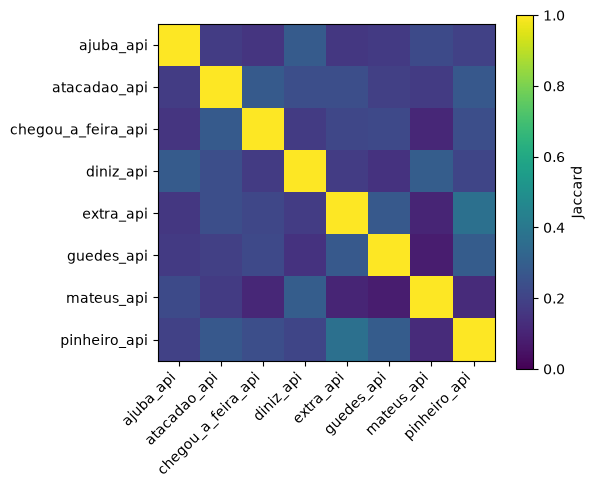

In [11]:
tabela_vocab = pd.Series({
    "tipos de token (normalizado)": vocabulario["tipos_normalizados"],
    "hapax legomena (freq. 1)": vocabulario["hapax"],
    "dis legomena (freq. 2)": vocabulario["dis_legomena"],
    "tokens exclusivos de uma loja": vocabulario["tokens_exclusivos_uma_loja"],
    "  — com frequência ≥ 2": vocabulario["tokens_exclusivos_uma_loja_freq_min2"],
    "vocabulário do dicionário": vocabulario["vocabulario_dicionario"],
    "  — presente na base": vocabulario["tokens_dicionario_presentes_na_base"],
    "tokens da base fora do dicionário (OOV)": f"{vocabulario['fracao_oov_bruto']:.1%}",
})
display(tabela_vocab.to_frame("valor"))

jaccard = eda.calcular_jaccard_entre_lojas(base)
fora_diagonal = jaccard.where(~pd.DataFrame(
    [[i == j for j in jaccard.columns] for i in jaccard.index], index=jaccard.index, columns=jaccard.columns))
print(f"Jaccard entre pares de lojas: mín {fora_diagonal.min().min():.2f}, máx {fora_diagonal.max().max():.2f}, "
      f"média {fora_diagonal.stack().mean():.2f}")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(jaccard.to_numpy(), vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(jaccard))); ax.set_xticklabels(jaccard.columns, rotation=45, ha="right")
ax.set_yticks(range(len(jaccard))); ax.set_yticklabels(jaccard.index)
fig.colorbar(im, ax=ax, label="Jaccard"); plt.tight_layout(); plt.show()

**Interpretação.** Quatro números sustentam o argumento de baixo recurso e especialização de domínio:
- **37% do vocabulário é hapax** (3.723 de 10.031 tipos aparecem uma única vez): a cauda longa é grande e um modelo genérico verá a maior parte desses tokens poucas vezes ou nunca.
- **5.976 tokens (60%) são exclusivos de uma única loja** — e 2.253 deles aparecem mais de uma vez, então não é só efeito de hapax: cada rede tem vocabulário próprio (abreviações e marcas regionais).
- **Jaccard entre lojas fica entre 0,08 e 0,37**: duas redes compartilham, no máximo, pouco mais de um terço do vocabulário. Esse e o número anterior valem para a fatia principal (produto × produto, entre lojas).
- **92% dos tipos de token da base não existem no vocabulário do dicionário**, e 296 das 1.095 palavras do dicionário nunca aparecem na base. A ponte entre os dois lados não é lexical. Este é o número da fatia secundária (produto × dicionário).

É isso que a L181 chama de "marcas e variantes regionais com baixa representação em corpora genéricos", agora com números. Também é o argumento mais direto contra TF-IDF/BM25 puros (L189): eles dependem de tokens compartilhados entre os dois lados do par, e 92% do vocabulário de um lado não existe no outro. Isso **sustenta**, mas não **prova**, a insuficiência dos métodos clássicos — a prova são os baselines da Fase 2.

## 6. Limpeza de dados

As Seções 2–5 descreveram a **base limpa**, que é a usada pelas tabelas de `latex/` e por todo o pipeline (ADR-0012). Esta seção documenta como ela é produzida a partir dos brutos e resolve os warnings do sanity check que pedem tratamento. Princípios (detalhados em `docs/limpeza_dados.md`):

1. `dados/brutos/` é imutável: a limpeza só escreve em `dados/processados/` (`produtos_limpos.parquet`, `dicionario_limpo.parquet`, `relatorio_limpeza.json`).
2. **Só se remove defeito objetivo de coleta.** Ruído linguístico (abreviação, inversão, variação de unidade, tipografia) é o objeto de estudo e nunca é removido.
3. Na dúvida, **marcar** em vez de remover.
4. A lógica vive em `scripts/01_coleta_dados.py` (`limpar_base`, testada; ADR-0012), primeiro passo de `make pipeline`. Este notebook só a executa e mostra as evidências.

### 6.1 Duplicatas exatas — C1 (resolve o warning §4 "1.129 linhas duplicadas exatas")

In [12]:
dup = bruto.duplicated(keep=False)
print(f"Linhas envolvidas em duplicação exata: {int(dup.sum()):,}; excedentes a remover: {int(bruto.duplicated().sum()):,}")
print("Por rede (excedentes):", bruto[bruto.duplicated()]["source"].value_counts().to_dict())
colunas_que_diferem = bruto[dup].groupby(list(bruto.columns), dropna=False).ngroups
print(f"Grupos de duplicatas: {colunas_que_diferem:,} — por definição, idênticos em todas as {bruto.shape[1]} colunas.")
amostra_grupo = bruto[dup].sample(1, random_state=SEED).iloc[0]
display(bruto[(bruto["source"] == amostra_grupo["source"]) & (bruto["product_id"] == amostra_grupo["product_id"])][VISIVEIS])

Linhas envolvidas em duplicação exata: 2,255; excedentes a remover: 1,129
Por rede (excedentes): {'extra_api': 1028, 'chegou_a_feira_api': 100, 'guedes_api': 1}
Grupos de duplicatas: 1,126 — por definição, idênticos em todas as 13 colunas.


,product_id,description,unit,price,location,source,collected_at
14932,1402738,Bebida Mista Alcoólica Gaseificada Green Apple Smirnoff Ice Lata 269ml,ml,5.79,"PI, Teresina, Vermelha",extra_api,2026-09-10 12:34:46.092
15528,1402738,Bebida Mista Alcoólica Gaseificada Green Apple Smirnoff Ice Lata 269ml,ml,5.79,"PI, Teresina, Vermelha",extra_api,2026-09-10 12:34:46.092


**Decisão: remover, mantendo a primeira ocorrência.** As linhas são idênticas nas 13 colunas — inclusive no timestamp e nas colunas que o modelo não vê —, então não há informação a perder em nenhuma delas e a escolha de qual manter é irrelevante (fixar "a primeira" só garante determinismo). A concentração em `extra_api` (1.028) e `chegou_a_feira_api` (100) indica coleta repetida, não catálogo.

### 6.2 Texto repetido na mesma loja — C2 (resolve o warning §4 "185 grupos de quase-duplicatas")

Antes de decidir, o que difere dentro de cada grupo?

In [13]:
sem_dup = coleta.remover_duplicatas_exatas(bruto)
sem_dup = sem_dup.assign(_desc=sem_dup["description"].map(coleta.normalizar_texto))
quase = sem_dup[sem_dup.duplicated(["_desc", "source"], keep=False)]
grupos_quase = quase.groupby(["_desc", "source"])
colunas = ["product_id", "description", "unit", "price", "location", "collected_at", "und_val", "und_med"]
difere = pd.Series({c: int(grupos_quase[c].nunique(dropna=False).gt(1).sum()) for c in colunas})
print(f"{grupos_quase.ngroups} grupos, {len(quase)} linhas. Em quantos grupos cada coluna difere:")
display(difere.to_frame("grupos"))
variacao_preco = (grupos_quase["price"].max() / grupos_quase["price"].min() - 1)
print(f"Diferença de preço dentro do grupo: mediana {variacao_preco.median():.1%}, máximo {variacao_preco.max():.0%}")
print("Linhas por rede:", quase["source"].value_counts().to_dict())
for chave in ["ACUCAR ALEGRE CRISTAL 1 KG", "CUECA LUPO AM BOXER MICROF.", "ADRIA GRANO DURO FARFALLE 500G"]:
    display(quase[quase["_desc"] == chave][["product_id", "description", "price", "source", "collected_at"]])

185 grupos, 394 linhas. Em quantos grupos cada coluna difere:


,grupos
product_id,185
description,10
unit,3
price,149
location,0
collected_at,0
und_val,0
und_med,0


Diferença de preço dentro do grupo: mediana 22.6%, máximo 1111%
Linhas por rede: {'guedes_api': 249, 'extra_api': 90, 'mateus_api': 22, 'ajuba_api': 9, 'chegou_a_feira_api': 8, 'pinheiro_api': 8, 'diniz_api': 6, 'atacadao_api': 2}


,product_id,description,price,source,collected_at
22109,39689,ACUCAR ALEGRE CRISTAL 1 KG,3.49,guedes_api,2026-09-10 12:37:11.954
22110,17932,ACUCAR ALEGRE CRISTAL 1 KG,3.19,guedes_api,2026-09-10 12:37:11.954


,product_id,description,price,source,collected_at
22393,20664,CUECA LUPO AM BOXER MICROF.,33.35,guedes_api,2026-09-10 12:37:11.954
22394,17647,CUECA LUPO AM BOXER MICROF.,34.79,guedes_api,2026-09-10 12:37:11.954
22395,18338,CUECA LUPO AM BOXER MICROF.,34.79,guedes_api,2026-09-10 12:37:11.954
22396,17649,CUECA LUPO AM BOXER MICROF.,34.79,guedes_api,2026-09-10 12:37:11.954
22397,17645,CUECA LUPO AM BOXER MICROF.,34.79,guedes_api,2026-09-10 12:37:11.954
22398,17644,CUECA LUPO AM BOXER MICROF.,34.79,guedes_api,2026-09-10 12:37:11.954
22399,29211,CUECA LUPO AM BOXER MICROF.,33.35,guedes_api,2026-09-10 12:37:11.954


,product_id,description,price,source,collected_at
20932,39335,ADRIA GRANO DURO FARFALLE 500G,11.39,guedes_api,2026-09-10 12:37:11.954
20933,39336,ADRIA GRANO DURO FARFALLE 500G,11.39,guedes_api,2026-09-10 12:37:11.954


**Decisão: manter e marcar `texto_repetido_na_loja`.** Em **todos** os 185 grupos o `product_id` difere, e em **nenhum** o timestamp, o local ou a unidade estruturada diferem. Isso descarta a hipótese de "atualização de preço durante o dia" (não há dois momentos de coleta) e também a de linha duplicada (os ids são diferentes). Em 149 grupos o preço difere (mediana +22,6%). O cenário mais coerente é o de **SKUs distintos do catálogo da loja que compartilham o mesmo nome** — `CUECA LUPO AM BOXER MICROF.` tem 7 ids, provavelmente tamanhos e cores que não estão no texto. Não há prova de defeito de coleta, então não se remove.

**O que a flag implica adiante:** ao montar candidatos e sortear pares para anotação (tarefas 1.2/1.4), o script 03 deve deduplicar por texto normalizado, para não anotar a mesma descrição duas vezes. Como o split é por produto canônico, textos idênticos caem na mesma partição — sem risco de vazamento.

### 6.3 Preço zero — C3 (resolve o warning §5 "Preços iguais a zero: 1")

In [14]:
display(bruto.loc[bruto["price"] <= 0, VISIVEIS])

,product_id,description,unit,price,location,source,collected_at
2233,14076,Fórmula Infantil NAN Comfor HMO de 6 a 12 meses 800g,UND,0.0,"CE, Fortaleza, Papicu",atacadao_api,2026-09-10 12:28:58.394


**Decisão: manter e marcar `preco_invalido`, sem alterar o valor.** O texto do registro é íntegro e o preço não entra no matching (ADR-0011). Remover descartaria uma descrição válida sem nenhum ganho para o modelo.

### 6.4 Dicionário — C4 (resolve o warning §2 "2 colunas sem nome no CSV")

In [15]:
print("Colunas no CSV:", list(dicionario_bruto.columns))
print("Nulos nas colunas sem nome:", dicionario_bruto.filter(like="Unnamed").isna().sum().to_dict())
print("Colunas após limpeza:", list(coleta.limpar_dicionario(dicionario_bruto).columns))

Colunas no CSV: ['desc_alim', 'codg_item1', 'cod_padrao', 'Unnamed: 3', 'Unnamed: 4']
Nulos nas colunas sem nome: {'Unnamed: 3': 1593, 'Unnamed: 4': 1593}
Colunas após limpeza: ['desc_alim', 'codg_item1', 'cod_padrao']


**Decisão: remover as duas colunas**, 100% vazias, artefato do CSV original. As 1.593 entradas permanecem intactas.

### 6.5 Colunas do matcher ALTA — C5 (ADR-0011)

A base limpa é a entrada de tudo que vem depois (blocagem, anotação, partição). Por isso `codg_item`, `desc_ref` e `match_score` **não entram nela**, com assert no código: o baseline "ALTA atual" as lê direto dos brutos, só depois de congelar o teste.

### 6.6 Limitações documentadas, sem tratamento

| Warning do sanity check | Por que não tratar |
|---|---|
| `codg_item`/`desc_ref` ausentes em 19,2% | Imputar seria inventar predições do matcher ALTA — mudaria o baseline, não os dados de treino/teste. O baseline é reportado nas duas versões (condicionada e total). |
| `cod_padrao` com 82,7% no valor 99 | Significado não confirmado; o `main.tex` já não o usa como categoria. Mantido no dicionário, sem uso. |
| Unidade estruturada ausente (5,8% / 2,0%) | A Seção 4.3 mostrou que o texto quase nunca a recupera; imputar criaria dado falso. Afeta só a supervisão distante. |
| Coleta de um único dia | Limitação da base, não defeito. Citar no §4.7. |

### 6.7 Execução e resultado

In [16]:
# `relatorio` e `base` vêm da execução do script 01 na célula de setup.
assert not {"codg_item", "desc_ref", "match_score"} & set(base.columns), "ADR-0011"
display(pd.Series({k: v for k, v in relatorio.items()}).to_frame("relatório"))


def resumo(df):
    v = eda.medir_vocabulario(df, dicionario)
    return {
        "registros": len(df),
        "redes": df["source"].nunique(),
        "locais": df["location"].nunique(),
        "produtos únicos (source, product_id)": len(df[["source", "product_id"]].drop_duplicates()),
        "descrições únicas (normalizadas)": df["description"].map(eda.normalizar_para_comparacao).nunique(),
        "vocabulário (tipos normalizados)": v["tipos_normalizados"],
        "hapax": v["hapax"],
        "OOV vs. dicionário": round(v["fracao_oov_bruto"], 4),
        "grupos de inversão entre lojas": eda.detectar_inversoes_de_ordem(df)["grupos_com_inversao_entre_lojas"],
    }


antes_depois = pd.DataFrame({"bruto": resumo(bruto), "limpo": resumo(base)})
antes_depois["diferença"] = antes_depois["limpo"] - antes_depois["bruto"]
display(antes_depois)

,relatório
registros_brutos,30259
duplicatas_exatas_removidas,1129
registros_limpos,29130
grupos_texto_repetido_na_loja,185
linhas_texto_repetido_na_loja,394
precos_invalidos,1
colunas_removidas_dicionario,"[Unnamed: 3, Unnamed: 4]"


,bruto,limpo,diferença
registros,30259.0000,29130.0000,-1129.0
redes,8.0000,8.0000,0.0
locais,7.0000,7.0000,0.0
"produtos únicos (source, product_id)",29130.0000,29130.0000,0.0
descrições únicas (normalizadas),28240.0000,28240.0000,0.0
vocabulário (tipos normalizados),10031.0000,10031.0000,0.0
hapax,3612.0000,3723.0000,111.0
OOV vs. dicionário,0.9203,0.9203,0.0
grupos de inversão entre lojas,376.0000,376.0000,0.0


**Interpretação.** A limpeza remove **1.129 registros (3,7%)**, todos duplicatas exatas, e **nenhum produto**: os 29.130 produtos únicos, as 28.240 descrições únicas, o vocabulário de 10.031 tipos, a taxa de OOV e os 376 grupos de inversão ficam idênticos. A única métrica textual que muda é o hapax (+111), porque tokens que só apareciam duas vezes por causa de uma linha duplicada passam a ter frequência 1 — a contagem anterior estava inflada pela duplicação. Ou seja: a limpeza tira redundância de coleta sem tocar no fenômeno estudado.

## 7. Conclusão: dos achados ao `main.tex`

| `main.tex` | Afirmação | Achado que sustenta |
|---|---|---|
| L170 | "nomes radicalmente distintos" | sobreposição exata entre lojas de 2,1%; 27,6% dos tipos do texto original são só variação de caixa/acento |
| L177 | abreviações e truncamentos | 3,4% com marca explícita (piso); exemplos reais (§4.1) |
| L178 | inversão na ordem dos tokens | 376 grupos com os mesmos tokens em ordens diferentes entre lojas (cota inferior) |
| L179 | unidades alternativas | grama em 5 grafias, litro em 4; unidade colada em 90,3% das descrições |
| L180 | granularidade descritiva | PDV 38,7 caracteres / 6,3 tokens vs. dicionário 18,0 / 2,9 |
| L181 | marcas/variantes regionais pouco representadas | 37% hapax; 60% dos tokens exclusivos de uma loja; Jaccard entre lojas 0,08–0,37; 92% OOV |
| L182 | ruído tipográfico | 74,2% sem acento, 24,0% em caixa alta |
| L185–187 | Tabela de heterogeneidade | pares de mesmo SKU conferidos pelo autor (`candidatos_heterogeneidade.csv` → `configs/eda.yaml` → `tab_heterogeneidade_exemplos.tex`); `tab_exemplos_ruido.tex` ilustra os tipos de ruído |
| L189 | métodos clássicos insuficientes | inversão e 92% de OOV **sustentam**; a prova são os baselines (Fase 2) |
| L344 (§4.7) | caracterização da base | todos os números acima, mais as limitações abaixo |

**Inconsistências com o `main.tex` identificadas por esta EDA** (registradas aqui; o `main.tex` foi revisado à luz delas em 2026-10-06):
1. §4.7: "30.260 registros" — são 30.259 no arquivo e **29.130 na base limpa**, que é a usada daqui em diante.
2. §4.7: "número de estabelecimentos" — dos 7 locais, `CE, Várias Unidades` é um agregado: **6 estabelecimentos + 1 agregado**.
3. Seção 1: "foram analisados e mostram-se insuficientes" está no pretérito — a EDA sustenta o argumento, mas a análise comparativa só existe depois dos baselines da Fase 2.

**Daqui em diante.** A base oficial do pipeline é `dados/processados/produtos_limpos.parquet` (29.130 registros, sem as colunas do matcher ALTA) e `dicionario_limpo.parquet` (1.593 entradas), gravadas pelo script 01 e regeneradas por `make pipeline`. Ficam documentadas, não escondidas, as limitações remanescentes: **coleta de um único dia** (sem série temporal), **`codg_item` ausente em 19,2%** (afeta só o baseline "ALTA atual") e **`cod_padrao` inutilizável como categoria**. A próxima etapa é a **blocagem TF-IDF/BM25 (tarefa 1.2)**, que deve deduplicar por texto normalizado (flag `texto_repetido_na_loja`) e medir o recall da blocagem isoladamente.